<a href="https://colab.research.google.com/github/LinaMariaCastro/curso-ia-para-economia/blob/main/clases/4_Aprendizaje_no_supervisado/3_Taller_PCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



# **Inteligencia Artificial con Aplicaciones en Economía I**

- 👩‍🏫 **Profesora:** [Lina María Castro](https://www.linkedin.com/in/lina-maria-castro)  
- 📧 **Email:** [lmcastroco@gmail.com](mailto:lmcastroco@gmail.com)  
- 🎓 **Universidad:** Universidad Externado de Colombia - Facultad de Economía

# **Taller: Creación de un Índice de Clima de Inversión con Análisis de Componentes Principales (PCA)**

**IMPORTANTE**: Guarda una copia de este notebook en tu Google Drive o computador.

**Taller en parejas**

**Nombres estudiantes:**

- Juan Sebastian Mendoza Parada

**Forma de entrega:**

- Nombrar el archivo de la siguiente forma:“Taller_PCA_apellidos.ipynb”.
- Suba el Jupyter Notebook a su cuenta en Github y envíe el link en el siguiente Forms: https://forms.cloud.microsoft/r/ZZX1AFUsPP.

**IMPORTANTE:** No se recibirán talleres en Google Colab, el notebook debe estar subido en Github.

**Plazo de entrega:**

21 de octubre de 2026, máximo a las 11:59 p.m. Tenga en cuenta que luego de esa hora el formulario en forms se cierra. El Jupupyter Notebook también debe quedar subido en Github antes de esa hora.

**Instrucciones Generales:**

Completa el código en las celdas marcadas con `### TU CÓDIGO AQUÍ ###`. Puedes añadir más celdas si lo requieres.

### Contexto

**Escenario:** Eres un científico de datos recién contratado como consultor experto por el **Ministerio de Comercio, Industria y Turismo (MinCIT)** de Colombia. Tu tarea principal es crear un **'Índice de Clima para la Inversión'** cuantitativo que permita clasificar y comparar el entorno competitivo de los países de América Latina y el Caribe. Este índice orientará las estrategias de integración regional y las políticas para atraer Inversión Extranjera Directa (IED).

**Objetivo:** Utilizando la base de datos de indicadores provista (preparada para este análisis) y la técnica de **Análisis de Componentes Principales (PCA)**, deberás extraer la "variable latente" que resume el clima de inversión, interpretar sus pesos económicos y presentar un ranking de países con recomendaciones ejecutivas.


## Ejercicio 1: Configuración Inicial, Carga y Exploración de Datos

1.1 Importa las librerías necesarias

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [2]:
pd.options.display.max_columns = None
pd.options.display.float_format = '{:,.2f}'.format
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

1.2 Carga el dataset "Indicators.csv" que se encuentra en el repositorio del curso, carpeta "datasets". El dataframe debe llamarse "df_indicators".

In [3]:
url_indicators = 'https://raw.githubusercontent.com/LinaMariaCastro/curso-ia-para-economia/main/datasets/4_Aprendizaje_no_supervisado/Indicators.csv'
df_indicators = pd.read_csv(url_indicators)
df_indicators.head()

,CountryCode,IndicatorCode,Year,Value
0,CHL,NV.AGR.TOTL.ZS,2014,6.75
1,CHL,NE.TRD.GNFS.ZS,2014,74.31
2,CHL,NY.GDP.MKTP.KD.ZG,2014,7.65
3,CHL,FP.CPI.TOTL.ZG,2014,12.62
4,CHL,GC.DOD.TOTL.GD.ZS,2014,42.83


In [ ]:
# Debe ser (121, 4)
print("Dimensiones del DataFrame Indicators:")
print(df_indicators.shape)

Dimensiones del DataFrame Indicators:
(121, 4)


In [5]:
print("\Información general del DataFrame:")
df_indicators.info()

\Información general del DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 121 entries, 0 to 120
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   CountryCode    121 non-null    object 
 1   IndicatorCode  121 non-null    object 
 2   Year           121 non-null    int64  
 3   Value          121 non-null    float64
dtypes: float64(1), int64(1), object(2)
memory usage: 3.9+ KB


<>:1: SyntaxWarning: invalid escape sequence '\I'
<>:1: SyntaxWarning: invalid escape sequence '\I'
/tmp/ipykernel_1100/302363835.py:1: SyntaxWarning: invalid escape sequence '\I'
  print("\Información general del DataFrame:")


1.3 Carga el dataset "Country.csv" que se encuentra en el repositorio del curso, carpeta "datasets". El dataframe debe llamarse "df_countries".

In [6]:
url_countries = 'https://raw.githubusercontent.com/LinaMariaCastro/curso-ia-para-economia/main/datasets/4_Aprendizaje_no_supervisado/Country.csv'
df_countries = pd.read_csv(url_countries)
df_countries.head()

,CountryCode,ShortName,Region
0,CHL,Chile,Latin America & Caribbean
1,PAN,Panamá,Latin America & Caribbean
2,CRI,Costa Rica,Latin America & Caribbean
3,COL,Colombia,Latin America & Caribbean
4,PER,Perú,Latin America & Caribbean


In [7]:
# Debe ser (14, 3)
print("Dimensiones del DataFrame Countries:")
print(df_countries.shape)

Dimensiones del DataFrame Countries:
(14, 3)


In [9]:
print("\nInformación general del DataFrame:")
df_countries.info()


Información general del DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   CountryCode  14 non-null     object
 1   ShortName    14 non-null     object
 2   Region       14 non-null     object
dtypes: object(3)
memory usage: 468.0+ bytes


### Ejercicio 2: Selección y Preparación de Datos

Para el análisis del MinCIT, hemos preseleccionado un conjunto de variables clave.

2.1. Utiliza el diccionario para modificar los códigos de los indicadores por sus descripciones

In [18]:
nombre_indicadores = {
    'NV.AGR.TOTL.ZS': 'Agricultura (% del PIB)',
    'NE.TRD.GNFS.ZS': 'Comercio (% del PIB)',
    'NY.GDP.MKTP.KD.ZG': 'Crecimiento del PIB (%)',
    'FP.CPI.TOTL.ZG': 'Inflación (%)',
    'GC.DOD.TOTL.GD.ZS': 'Deuda del gob. central (% del PIB)',
    'SE.XPD.TOTL.GD.ZS': 'Gasto en educación (% del PIB)',
    'SH.XPD.CHEX.GD.ZS': 'Gasto en salud (% del PIB)',
    'IQ.CPA.BREG.XQ': 'Facilidad para hacer negocios',
    'IC.LGL.DURS': 'Días para cumplir contratos',
    'TX.VAL.MRCH.XD.WD': 'Exportaciones (US$)',
    'TM.VAL.MRCH.XD.WD': 'Importaciones (US$)'
}

In [19]:
df_indicators['IndicatorCode'] = df_indicators['IndicatorCode'].replace(nombre_indicadores)
df_indicators.head()

,CountryCode,IndicatorCode,Year,Value
0,CHL,Agricultura (% del PIB),2014,6.75
1,CHL,Comercio (% del PIB),2014,74.31
2,CHL,Crecimiento del PIB (%),2014,7.65
3,CHL,Inflación (%),2014,12.62
4,CHL,Deuda del gob. central (% del PIB),2014,42.83


2.2. Utiliza pivot table para crear un nuevo dataframe donde se encuentren los países como filas y los indicadores como columnas. Llama a este dataframe "df_pivot". No olvides colocar .reset_index() para que la columna de código de países quede como una columna y no como el índice.

In [20]:
df_pivot = df_indicators.pivot_table(index='CountryCode',
                                     columns='IndicatorCode',
                                     values='Value').reset_index()
df_pivot.head()

IndicatorCode,CountryCode,Agricultura (% del PIB),Comercio (% del PIB),Crecimiento del PIB (%),Deuda del gob. central (% del PIB),Días para cumplir contratos,Exportaciones (US$),Facilidad para hacer negocios,Gasto en educación (% del PIB),Gasto en salud (% del PIB),Importaciones (US$),Inflación (%)
0,ARG,11.73,32.43,-0.45,73.07,873.48,"20,153,725,105.95",2.19,2.38,4.09,"18,058,208,718.45",44.28
1,BOL,NaN,54.39,1.76,66.69,798.96,"39,036,984,373.93",NaN,5.37,5.05,"36,977,180,000.81",36.05
2,BRA,12.79,60.18,2.59,57.20,741.68,"56,043,860,610.92",3.57,4.56,5.31,"50,026,448,161.33",25.60
3,CHL,6.75,74.31,7.65,42.83,535.92,"90,542,560,043.59",5.88,6.38,8.29,"80,536,582,307.19",12.62
4,COL,6.92,59.96,6.60,47.95,633.90,NaN,NaN,6.34,6.30,"67,424,196,254.97",11.61


2.3. Crea el dataframe "df_final", realizando un merge entre "df_pivot" y "df_countries" con el fin de agregar el nombre de los países.

In [21]:
df_final = pd.merge(df_pivot, df_countries, on='CountryCode', how='left')
df_final.head()

,CountryCode,Agricultura (% del PIB),Comercio (% del PIB),Crecimiento del PIB (%),Deuda del gob. central (% del PIB),Días para cumplir contratos,Exportaciones (US$),Facilidad para hacer negocios,Gasto en educación (% del PIB),Gasto en salud (% del PIB),Importaciones (US$),Inflación (%),ShortName,Region
0,ARG,11.73,32.43,-0.45,73.07,873.48,"20,153,725,105.95",2.19,2.38,4.09,"18,058,208,718.45",44.28,Argentina,Latin America & Caribbean
1,BOL,NaN,54.39,1.76,66.69,798.96,"39,036,984,373.93",NaN,5.37,5.05,"36,977,180,000.81",36.05,Bolivia,Latin America & Caribbean
2,BRA,12.79,60.18,2.59,57.20,741.68,"56,043,860,610.92",3.57,4.56,5.31,"50,026,448,161.33",25.60,Brasil,Latin America & Caribbean
3,CHL,6.75,74.31,7.65,42.83,535.92,"90,542,560,043.59",5.88,6.38,8.29,"80,536,582,307.19",12.62,Chile,Latin America & Caribbean
4,COL,6.92,59.96,6.60,47.95,633.90,NaN,NaN,6.34,6.30,"67,424,196,254.97",11.61,Colombia,Latin America & Caribbean


2.4. Elimina las columnas "Region" y "CountryCode" y establece la columna 'ShortName' como el índice del dataframe

In [22]:
df_final = df_final.drop(columns=['Region', 'CountryCode'])
df_final = df_final.set_index('ShortName')
df_final.head()

,Agricultura (% del PIB),Comercio (% del PIB),Crecimiento del PIB (%),Deuda del gob. central (% del PIB),Días para cumplir contratos,Exportaciones (US$),Facilidad para hacer negocios,Gasto en educación (% del PIB),Gasto en salud (% del PIB),Importaciones (US$),Inflación (%)
ShortName,,,,,,,,,,,
Argentina,11.73,32.43,-0.45,73.07,873.48,"20,153,725,105.95",2.19,2.38,4.09,"18,058,208,718.45",44.28
Bolivia,NaN,54.39,1.76,66.69,798.96,"39,036,984,373.93",NaN,5.37,5.05,"36,977,180,000.81",36.05
Brasil,12.79,60.18,2.59,57.20,741.68,"56,043,860,610.92",3.57,4.56,5.31,"50,026,448,161.33",25.60
Chile,6.75,74.31,7.65,42.83,535.92,"90,542,560,043.59",5.88,6.38,8.29,"80,536,582,307.19",12.62
Colombia,6.92,59.96,6.60,47.95,633.90,NaN,NaN,6.34,6.30,"67,424,196,254.97",11.61


### Ejercicio 3: Limpieza de Datos (Imputación de Valores Faltantes)

En la vida real de un economista, los datos tienen huecos. El PCA requiere bases completas. Usaremos una estrategia de imputación por la media para resolver los NaN.

3.1. Revisa cuántos valores faltantes hay en cada columna

In [23]:
df_final.isnull().sum()

,0
Agricultura (% del PIB),4
Comercio (% del PIB),3
Crecimiento del PIB (%),0
Deuda del gob. central (% del PIB),4
Días para cumplir contratos,2
Exportaciones (US$),3
Facilidad para hacer negocios,5
Gasto en educación (% del PIB),3
Gasto en salud (% del PIB),4
Importaciones (US$),3


3.2. Para cada columna, utiliza el promedio del resto de países de Latinoamérica para imputar los valores faltantes. El resultado debe quedar en un dataframe llamado "df_final_imputed". Al final revisa que no haya quedado ningún valor faltante en las columnas del dataframe.

In [24]:
df_final_imputed = df_final.fillna(df_final.mean())
df_final_imputed.isnull().sum()


,0
Agricultura (% del PIB),0
Comercio (% del PIB),0
Crecimiento del PIB (%),0
Deuda del gob. central (% del PIB),0
Días para cumplir contratos,0
Exportaciones (US$),0
Facilidad para hacer negocios,0
Gasto en educación (% del PIB),0
Gasto en salud (% del PIB),0
Importaciones (US$),0


### Ejercicio 4: Matriz de Correlaciones y Estandarización de Variables

4.1. Grafica un mapa de calor para ver las correlaciones entre las variables.

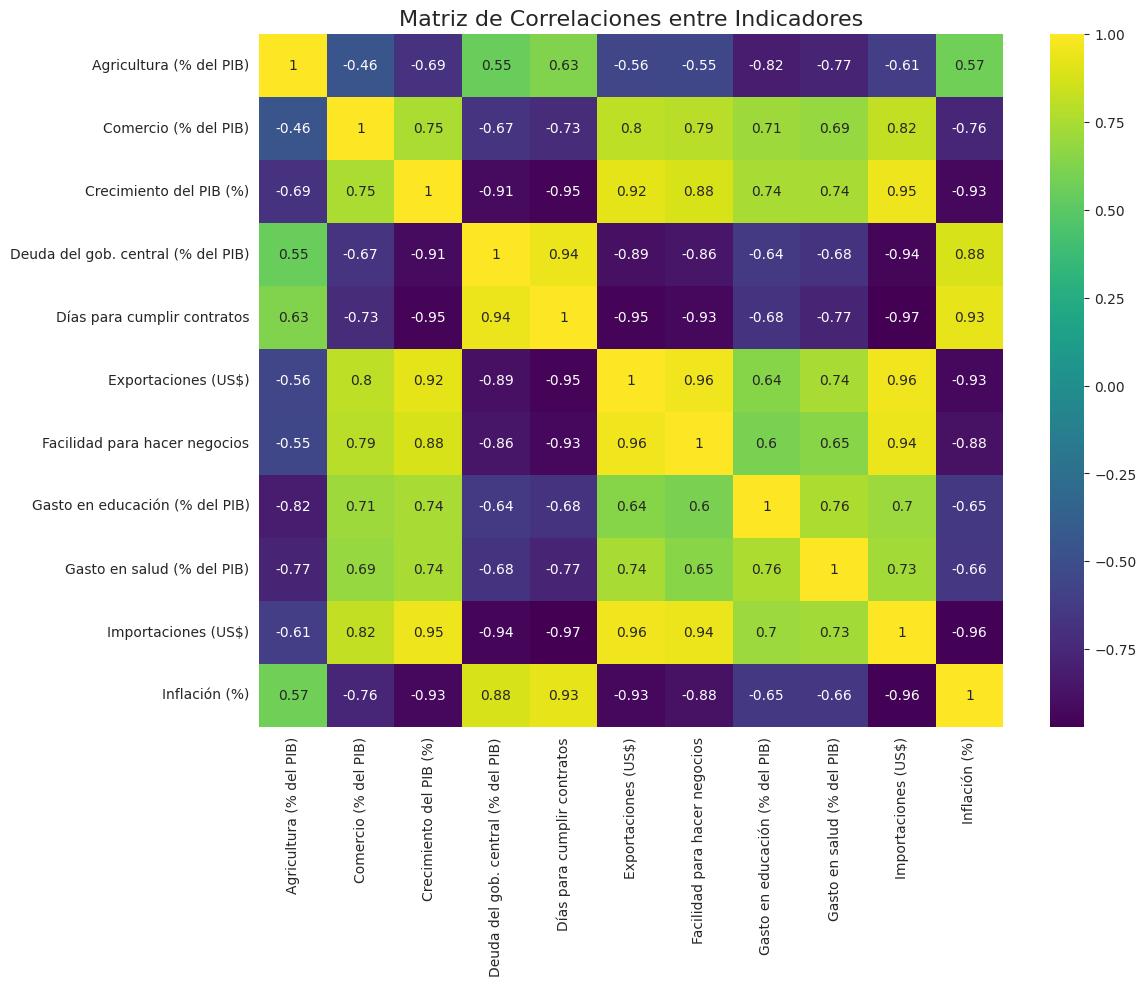

In [25]:
corr = df_final_imputed.corr().round(2)

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, cmap='viridis')
plt.title('Matriz de Correlaciones entre Indicadores', fontsize=16)
plt.show()

4.2. Interpreta los resultados resaltando las correlaciones más relevantes.

**Interpretación de la matriz de correlaciones:**

La correlacion nos muestra si dos variables se mueven juntas. En dado caso si el numero se acerca a 1 cuando sube la otra tambien sube, si esta cerca de -1, cuando sube la otra bajay si esta cerca de 0, significa que no hay mucha relacion.

Lo mas llamativo que encontre es que practicamnete todos los colores son extremos, es decir, que practicamente todas las variables estan muy relacionadas entre si.

Yo lo separaria en dos grupos en especifico, las variables buenas, como el crecimiento del PIB, exportaciones, importaciones, Facilidad en el comercio, educacion y salud, todas estan juntas con correlaciones bastantes altas, con algunas cercanas al 0.96. Y tambien estan las variables malas, que en palabras simples son las que afectan como tal al pais, como lo puede ser la alta correlacion que los paises con deuda tambien suelen tener una justicia mucho mas lenta.


4.3. Las exportaciones están en miles de millones de dólares y el crecimiento en porcentajes de un dígito. PCA busca varianzas, por lo que estandarizar (Media 0, Desviación 1) es un paso matemático obligatorio para no sesgar el modelo hacia las variables nominales grandes.  Estandariza todas las variables del dataframe y almacena el resultado en X_scaled.

In [26]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_final_imputed)

print("Dimensiones de X_scaled:", X_scaled.shape)

Dimensiones de X_scaled: (14, 11)


### Ejercicio 5: Aplicación de PCA

Vamos a correr PCA para identificar el número de componentes. Buscamos capturar la mayor cantidad de información (varianza) con la menor cantidad de dimensiones.

5.1. Corre PCA sobre X_scaled y calcula la varianza acumulada. Almacénala en la variable "varianza_acumulada".

In [27]:
pca = PCA()
pca.fit(X_scaled)

print("Varianza explicada por cada componente:")
print(pca.explained_variance_ratio_)

varianza_acumulada = np.cumsum(pca.explained_variance_ratio_)
print("\nVarianza acumulada:")
print(varianza_acumulada)

Varianza explicada por cada componente:
[8.04323856e-01 9.05376851e-02 4.11102033e-02 2.39395854e-02
 1.65075780e-02 1.00554931e-02 6.02055869e-03 4.15721369e-03
 2.30418041e-03 6.60514938e-04 3.83131616e-04]

Varianza acumulada:
[0.80432386 0.89486154 0.93597174 0.95991133 0.97641891 0.9864744
 0.99249496 0.99665217 0.99895635 0.99961687 1.        ]


5.2. Similar a como lo vimos en clase, grafica la varianza explicada acumulada por componente.

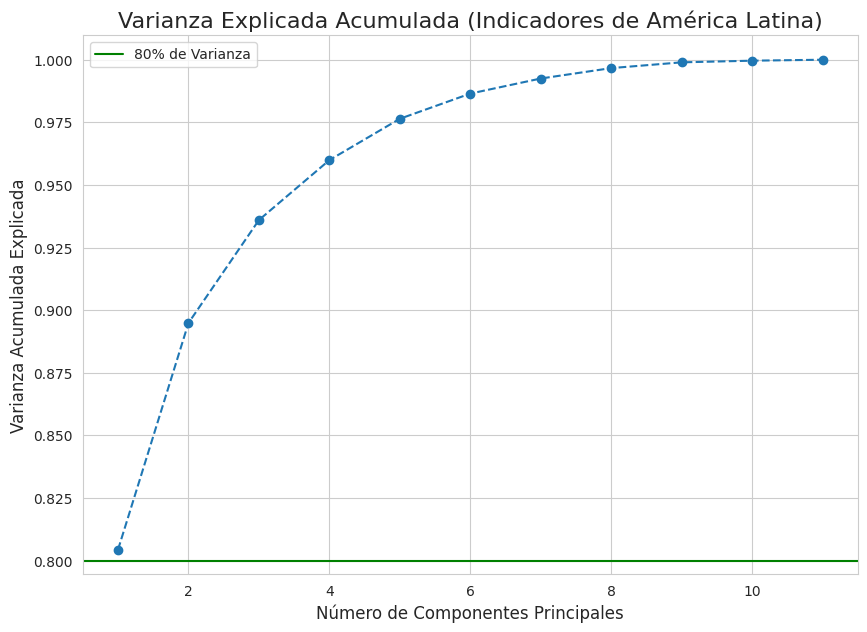

In [28]:
plt.figure(figsize=(10, 7))
plt.plot(range(1, len(varianza_acumulada) + 1), varianza_acumulada, marker='o', linestyle='--')
plt.title('Varianza Explicada Acumulada (Indicadores de América Latina)', fontsize=16)
plt.xlabel('Número de Componentes Principales', fontsize=12)
plt.ylabel('Varianza Acumulada Explicada', fontsize=12)
plt.axhline(y=0.8, color='g', linestyle='-', label='80% de Varianza')
plt.legend()
plt.show()

5.3. Realiza un análisis del gráfico anterior.

En el primer componente podemos ver como explica por si solo el 80.4% de la varianza total, superando el umbral de referencia. asi mismo el segundo eleva el acumulado de 89.5%, el aporte marginal cae drasticamente (9%), marcando el punto dequiebre de la curva. Por ultimo dadas las 11 variables estan altamente correlacionadas, un solo componente logra resumir eficazmente la informacion.

### Ejercicio 6: Interpretación Económica de los Componentes (Loadings)

Nos vamos a quedar con un solo componente. Vamor a analizar qué variables originales alimentan a este componente.

6.1. Corre nuevamente el PCA, pero ahora indicando que tenga en cuenta solo 1 componente. Almacena el modelo en "pca_final" y los resultados en "X_pca".

In [29]:
pca_final = PCA(n_components=1)
X_pca = pca_final.fit_transform(X_scaled)

print("Dimensiones del dataset original:", X_scaled.shape)
print("Dimensiones del dataset reducido:", X_pca.shape)
print("Varianza explicada por el componente 1:", pca_final.explained_variance_ratio_)

Dimensiones del dataset original: (14, 11)
Dimensiones del dataset reducido: (14, 1)
Varianza explicada por el componente 1: [0.80432386]


6.2. Grafica el mapa de calor de los loadings como lo vimos en clase

In [31]:

df_loadings = pd.DataFrame(pca_final.components_,
                           columns=df_final_imputed.columns,
                           index=['CP1'])
df_loadings

,Agricultura (% del PIB),Comercio (% del PIB),Crecimiento del PIB (%),Deuda del gob. central (% del PIB),Días para cumplir contratos,Exportaciones (US$),Facilidad para hacer negocios,Gasto en educación (% del PIB),Gasto en salud (% del PIB),Importaciones (US$),Inflación (%)
CP1,-0.24,0.28,0.32,-0.31,-0.33,0.32,0.31,0.27,0.28,0.33,-0.32


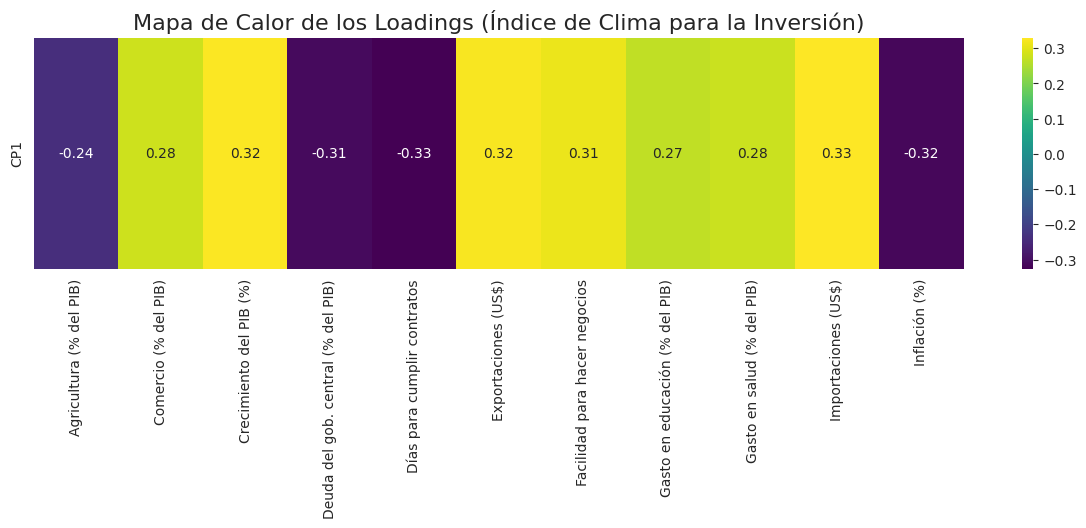

In [32]:
plt.figure(figsize=(15, 3))
sns.heatmap(df_loadings, annot=True, cmap='viridis', fmt='.2f')
plt.title('Mapa de Calor de los Loadings (Índice de Clima para la Inversión)', fontsize=16)
plt.show()

6.3. Realiza una interpretación de los loadings. ¿Cuáles variables tienen las cargas altas y positivas y cuáles las cargas altas y negativas? De acuerdo con este análisis, ¿consideras que efectivamente podemos utilizar el componente 1 como un índice del clima para la inversión en cada país de Latinoamérica? ¿por qué si o por qué no?

Los loadings representan el peso de cada variable dentro del Componente 1: los valores positivos elevan el puntaje del país, mientras que los negativos lo reducen. Al situarse todos entre 0.24 y 0.33, muestran que no hay una variable dominante, sino un aporte equilibrado del conjunto. El puntaje aumenta con indicadores clave para el inversionista extranjero (crecimiento del PIB, volumen de exportaciones/importaciones, facilidad para hacer negocios e inversión en salud y educación), y disminuye ante factores de riesgo o ineficiencia (alta inflación, deuda pública elevada, justicia lenta para cumplir contratos y un sector agrícola dominante). Por esta razón, el Componente 1 funciona de manera óptima como un índice de clima de inversión: resume el 80% de la información original en un solo número fácil de interpretar, donde una mayor puntuación refleja una economía en crecimiento, abierta al comercio y con reglas de juego claras.

### Ejercicio 7: Creación del 'Índice de Clima para la Inversión'

Asignaremos el CP1 como nuestro 'Índice de Clima para la Inversión' y construiremos el ranking regional.

In [34]:
df_final['Indice_Inversion'] = X_pca[:, 0]
df_final.head()

,Agricultura (% del PIB),Comercio (% del PIB),Crecimiento del PIB (%),Deuda del gob. central (% del PIB),Días para cumplir contratos,Exportaciones (US$),Facilidad para hacer negocios,Gasto en educación (% del PIB),Gasto en salud (% del PIB),Importaciones (US$),Inflación (%),Indice_Inversion
ShortName,,,,,,,,,,,,
Argentina,11.73,32.43,-0.45,73.07,873.48,"20,153,725,105.95",2.19,2.38,4.09,"18,058,208,718.45",44.28,-5.93
Bolivia,NaN,54.39,1.76,66.69,798.96,"39,036,984,373.93",NaN,5.37,5.05,"36,977,180,000.81",36.05,-1.93
Brasil,12.79,60.18,2.59,57.20,741.68,"56,043,860,610.92",3.57,4.56,5.31,"50,026,448,161.33",25.60,-1.24
Chile,6.75,74.31,7.65,42.83,535.92,"90,542,560,043.59",5.88,6.38,8.29,"80,536,582,307.19",12.62,4.89
Colombia,6.92,59.96,6.60,47.95,633.90,NaN,NaN,6.34,6.30,"67,424,196,254.97",11.61,2.13


7.1. Ordena el df_final por el índice de clima para la inversión de mayor a menor valor del índice.

In [35]:

df_final = df_final.sort_values(by='Indice_Inversion', ascending=False)
df_final[['Indice_Inversion']]


,Indice_Inversion
ShortName,
Chile,4.89
Panamá,3.89
Costa Rica,2.75
Colombia,2.13
Uruguay,1.09
México,0.97
Perú,0.66
United States,-0.14
Germany,-0.21


7.2. Convierte 'ShortName' en una columna del dataframe.

In [36]:
df_final = df_final.reset_index()
df_final.head()

,ShortName,Agricultura (% del PIB),Comercio (% del PIB),Crecimiento del PIB (%),Deuda del gob. central (% del PIB),Días para cumplir contratos,Exportaciones (US$),Facilidad para hacer negocios,Gasto en educación (% del PIB),Gasto en salud (% del PIB),Importaciones (US$),Inflación (%),Indice_Inversion
0,Chile,6.75,74.31,7.65,42.83,535.92,"90,542,560,043.59",5.88,6.38,8.29,"80,536,582,307.19",12.62,4.89
1,Panamá,5.80,NaN,6.89,43.42,555.93,"83,978,447,805.32",5.40,5.95,7.72,"76,338,244,613.60",8.11,3.89
2,Costa Rica,8.11,70.86,5.88,NaN,610.31,"78,236,959,844.64",5.53,5.64,6.77,"72,324,083,969.39",8.49,2.75
3,Colombia,6.92,59.96,6.60,47.95,633.90,NaN,NaN,6.34,6.30,"67,424,196,254.97",11.61,2.13
4,Uruguay,8.21,64.01,4.47,NaN,717.08,"63,598,148,937.21",NaN,5.63,6.65,"59,086,857,093.80",11.66,1.09


7.3. Utiliza un barplot para mostrar los resultados del Índice de Clima para la Inversión. En el eje y deben ir los países y en el eje X el puntaje del índice. No olvides colocar título al gráfico y a los ejes.

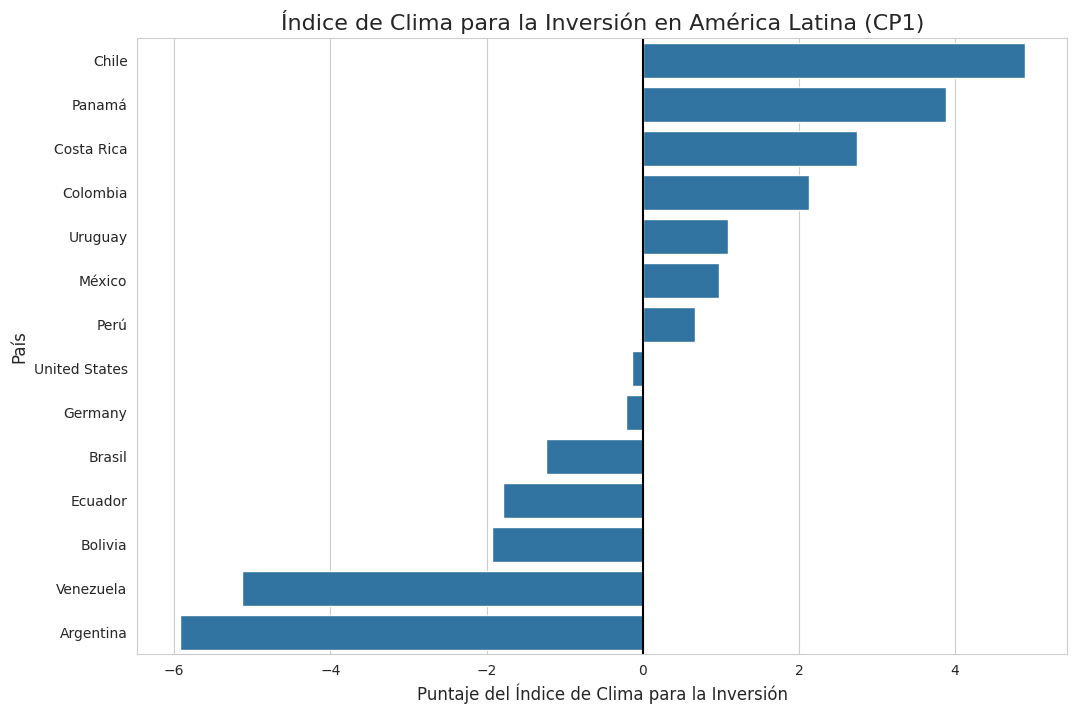

In [37]:
plt.figure(figsize=(12, 8))
sns.barplot(x='Indice_Inversion', y='ShortName', data=df_final)
plt.axvline(x=0, color='black', linestyle='-')
plt.title('Índice de Clima para la Inversión en América Latina (CP1)', fontsize=16)
plt.xlabel('Puntaje del Índice de Clima para la Inversión', fontsize=12)
plt.ylabel('País', fontsize=12)
plt.show()

7.4. Analiza los resultados del gráfico y redacta una conclusiones para el MinCIT sobre el clima de inversión en la región, quiénes son nuestros competidores en la atracción de capitales extranjeros y por qué, en qué son mejores que Colombia.

El índice muestra una región muy dividida. Chile, Panamá, Costa Rica y Colombia encabezan la lista porque crecen más, están más abiertas al comercio y tienen sus cuentas en orden. Argentina y Venezuela quedan muy atrás por la inflación, la deuda y la debilidad de sus instituciones.

Colombia es cuarta entre 14 países (puntaje de 2,13), muy por encima del promedio regional, sobre todo por el crecimiento del PIB (6,6%) y el gasto en educación (6,3% del PIB). Frente a los líderes sale peor en justicia (634 días para hacer cumplir un contrato), inflación (11,6%), apertura comercial (60% del PIB) y deuda pública (48% del PIB).

Para subir en el ranking, las prioridades deberían ser agilizar la resolución de disputas contractuales, bajar la inflación, mantener la disciplina fiscal y aprovechar mejor los acuerdos comerciales vigentes.

Dos advertencias sobre los datos. Las cifras faltantes de Colombia en exportaciones y facilidad para hacer negocios se completaron con el promedio regional, lo que podría subestimar su posición. Y los puntajes de Estados Unidos y Alemania dependen de tantos datos imputados que no sirven como referencia.
